## Information Retrieval Fundamentals #1 — Sparse vs Dense Retrieval & Evaluation Metrics: TF-IDF, BM25, Dense Retrieval and ColBERT


Note : If you run the notebook on Kaggle, it won't work. I made it work on my local. 

Notebook version of : https://mburaksayici.com/blog/2025/10/12/information-retrieval-1.html

To make it locally run, please run on : https://github.com/mburaksayici/InformationRetrievalTutorial

Information Retrieval could be defined as a field of study interested in ways to finding relevant material of an unstructured nature (usually text) from a collection of data (i.e.: files stored in your file system) to satisfy user information need.

We’ll explore evaluation metrics and fundamental retrieval algorithms — from sparse methods, TF-IDF and BM25, to vector-based approaches such as Dense Retrieval, Dense Passage Retrieval, and ColBERT — comparing their principles and real-world performance, on CISI data.


<p align="center">
  <img 
    src="https://upload.wikimedia.org/wikipedia/commons/thumb/4/48/Language_model_in_Deepmind%27s_2021_Retro_for_RAG.svg/2560px-Language_model_in_Deepmind%27s_2021_Retro_for_RAG.svg.png"
    alt="Language Model in DeepMind’s 2021 RETRO for RAG"
    width="700"
    style="border-radius:12px; box-shadow:0 0 10px rgba(0,0,0,.2);"
  />
  <br/>
  <em>Figure: How retrieval augments language models to ground generation. (DeepMind RETRO, 2021)</em>
</p>


In [ ]:
import os 
folder = "."
text_path = os.path.join(folder,"CISI.ALL")
query_path  = os.path.join(folder,"CISI.QRY")
relevancy_path = os.path.join(folder,"CISI.REL")

# !unzip archive.zip -d cisi/

## 📑 Table of Contents

- [Information Retrieval Techniques](#information-retrieval-techniques)
  - [The CISI Data](#the-cisi-data)
  - [Sparse Retrieval](#sparse-retrieval)
    - [TF-IDF](#tf-idf)
      - [Word "and"](#word-and)
      - [Word "quasar"](#word-quasar)
    - [TF](#tf)
    - [IDF](#idf)
    - [Query](#query)
  - [Evaluation Algorithms](#evaluation-algorithms)
    - [Mean Reciprocal Rank (MRR)](#-mean-reciprocal-rank-mrr)
    - [Mean Average Precision@k](#mean-average-precisionk)
    - [Recall@k](#recallk)
    - [Fallout@k](#falloutk)
    - [Hit Rate @k](#hit-rate-k)
    - [Discounted Cumulative Gain](#discounted-cumulative-gain)
  - [BM25](#bm25)
  - [Dense Retrieval](#dense-retrieval)
  - [Dense Passage Retrieval](#dense-passage-retrieval)
  - [ColBERT](#colbert)
    - [Step 1 – Query and Document Embeddings](#step-1--query-and-document-embeddings)
    - [Step 2 – Token-Level Similarity](#step-2--token-level-similarity)
    - [Step 3 – MaxSim and Aggregation](#step-3--maxsim-and-aggregation)
- [📚 References & Resources](#-references--resources)
  - [Classical Information Retrieval](#classical-information-retrieval)
  - [Dense Retrieval & Sentence Embeddings](#dense-retrieval--sentence-embeddings)
  - [Late Interaction & Reranking](#late-interaction--reranking)
  - [Evaluation Metrics](#evaluation-metrics)
  - [Kaggle Notebooks Referenced](#kaggle-notebooks-referenced)
  - [Additional Libraries / Tools](#additional-libraries--tools)
  - [Image & Media Credits](#image--media-credits)




Note:

- I’ll use any resource that helps me to prepare faster.
- I’m not directly working for interviews, but preparing for them makes me learn so many stuff, for years(check main page of website for 8 yo youtube channel).
- I’ll cite every content I use.
- I’ll agressively reference anything I believe explained things better than me.
- %90 of the content is generated by me, %10 is either AI or formatted by AI. I used it to save time, not to generate.

### The CISI Data

The CISI dataset contains 1,460 documents (CISI.ALL) and 112 queries (CISI.QRY). Input to a model is a query from CISI.QRY, and the expected output is a list of relevant document IDs. The CISI.REL file provides the ground-truth matches for evaluation.


CISI.ALL → full text of all documents.

CISI.QRY → text of the queries.

CISI.REL → gold standard mapping of queries to relevant documents.


Simply what we want to do with this data to get relevant documents with respect to the queries in CISI.QRY, reading text with CISI.ALL and calculate relevancy of our retrieval systems with CISI.REL data.




In [ ]:
# Kudos to Sahana.Venkatesh : https://www.kaggle.com/code/sahanavejlr/evaluating-ir-on-kaggle-dataset 
def read_documents (text_path):
    f = open (text_path)
    merged = " "
    # the string variable merged keeps the result of merging the field identifier with its content
    
    for a_line in f.readlines ():
        if a_line.startswith ("."):
            merged += "\n" + a_line.strip ()
        else:
            merged += " " + a_line.strip ()
    # updates the merged variable using a for-loop
    
    documents = {}
    
    content = ""
    doc_id = ""
    # each entry in the dictioanry contains key = doc_id and value = content
    
    for a_line in merged.split ("\n"):
        if a_line.startswith (".I"):
            doc_id = int(a_line.split (" ") [1].strip())
        elif a_line.startswith (".X"):
            documents[doc_id] = content
            content = ""
            doc_id = ""
        else:
            content += a_line.strip ()[3:] + " "
            #Extract after . a letter and a space
    f.close ()
    return documents

# print out the size of the dictionary and the content of the very first article
documents = read_documents (text_path)
print (f"{len (documents)} documents exists")
sample_doc = documents.get (1)
print (f"Sample doc : {sample_doc}") 
–

1460 documents exists
Sample doc :  18 Editions of the Dewey Decimal Classifications Comaromi, J.P. The present study is a history of the DEWEY Decimal Classification.  The first edition of the DDC was published in 1876, the eighteenth edition in 1971, and future editions will continue to appear as needed.  In spite of the DDC's long and healthy life, however, its full story has never been told.  There have been biographies of Dewey that briefly describe his system, but this is the first attempt to provide a detailed history of the work that more than any other has spurred the growth of librarianship in this country and abroad. 


In [ ]:
def read_queries(query_path):
    with open(query_path) as f:
        merged = ""
        for a_line in f.readlines():
            if a_line.startswith("."):
                merged += "\n" + a_line.strip()
            else:
                merged += " " + a_line.strip()

    queries = {}
    content = ""
    qry_id = ""

    for a_line in merged.split("\n"):
        if a_line.startswith(".I"):
            if content != "":
                queries[qry_id] = content
                content = ""
                qry_id = ""
            qry_id = a_line.split(" ")[1].strip()
        elif a_line.startswith(".W") or a_line.startswith(".T"):
            content += a_line.strip()[3:] + " "

    if qry_id != "":
        queries[qry_id] = content

    return queries



In [ ]:
# print out the length of the dictionary and the content of the first query
queries = read_queries(query_path)


In [ ]:
print(f"There are {len(queries)} queries to be evaluated")


There are 112 queries to be evaluated


In [ ]:
def read_mappings(relevancy_path):
    mappings = {}
    with open(relevancy_path) as f:
        for a_line in f.readlines():
            voc = a_line.strip().split()
            if not voc:
                continue
            key = voc[0].strip()
            current_value = voc[1].strip()
            value = mappings.get(key, [])
            value.append(current_value)
            mappings[key] = value
    return mappings

# print out some information about the mapping data structure
mappings = read_mappings(relevancy_path=relevancy_path)
print(len(mappings))
print(mappings.keys())
print(mappings.get("1"))


76
dict_keys(['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '37', '39', '41', '42', '43', '44', '45', '46', '49', '50', '52', '54', '55', '56', '57', '58', '61', '62', '65', '66', '67', '69', '71', '76', '79', '81', '82', '84', '90', '92', '95', '96', '97', '98', '99', '100', '101', '102', '104', '109', '111'])
['28', '35', '38', '42', '43', '52', '65', '76', '86', '150', '189', '192', '193', '195', '215', '269', '291', '320', '429', '465', '466', '482', '483', '510', '524', '541', '576', '582', '589', '603', '650', '680', '711', '722', '726', '783', '813', '820', '868', '869', '894', '1162', '1164', '1195', '1196', '1281']


We are querying this:

In [ ]:
queries.get("1")

'What problems and concerns are there in making up descriptive titles? What difficulties are involved in automatically retrieving articles from approximate titles? What is the usual relevance of the content of articles to their titles? '

Most relevant docs are: 


In [ ]:
mappings.get("1")[:10]

['28', '35', '38', '42', '43', '52', '65', '76', '86', '150']

And most relevant doc is



In [ ]:
documents.get(int(str(mappings.get("1")[0])))

'A Note on the Pseudo-Mathematics of Relevance Taube, M. Recently a number of articles, books, and reports dealing with information systems, i.e., document retrieval systems, have advanced the doctrine that such systems are to be evaluated in terms of the degree or percentage of relevancy they provide. Although there seems to be little agreement on what relevance means, and some doubt that it is quantifiable, there is, nevertheless, a growing agreement that a fixed and formal relationship exists between the relevance and the recall performance of any system.  Thus, we will find in the literature both a frankly subjective notion of relevance as reported by individual users, and equations, curves, and mathematical formulations which presumably provide numerical measures of the recall and relevance characteristics of information systems.  This phenomenon of shifting back and forth from an admittedly subjective and non-mathematical term to equations in which the same term is given a mathem

### Sparse Retrieval

- Definition: Classic keyword-based retrieval.
- Techniques: TF-IDF, BM25, Query Likelihood Models.
- Strength: Precise on keywords, fast, explainable.
- Weakness: Struggles with semantic matching.

#### TF-IDF

Term Frequency–Inverse Document Frequency is a measure of importance of a word to a document in a collection or corpus, adjusted for the fact that some words appear more frequently in general. (Wikipedia)


In order to implement that, we'll calculate the frequency of a word (term), considering how many times it also appears in other documents so that its descriptive power is low.

For example, the word “this” appears in almost every document, so its IDF is very low. Even if it appears frequently in a particular document, TF-IDF considers it not very relevant because it’s common across the collection.



![TF-IDF formula](https://mungingdata.wordpress.com/wp-content/uploads/2017/11/equation.png)

Let's take two cases: 

##### Word "and": 
  
* TF section, checks the relevance in single doc,  of formula is as close to 1, or it's more than other words because it's used too much in a single document on average, so it's the word closest to 1 amongst the corpus. 

* IDF, rating the scarcity and assumes that rarer the word, most important it is. The word "and" appears almost in all documents so it's found in every documents, it'll be nearly log 1, penalising because algorithm designed to say that "oh this word is everywhere, probably the user doesn't search for that word."

##### Word "quasar":

* TF, checks the relevance in single doc, section of formula is appearance/word in doc, or it's more than other words because it's used too much in a single document on average, so it's near zero. 

* IDF, emphasizing scarcity, this word appears in one document, out of 10000 documents so the score will be boosted  by log (10000/1).




#### TF 

In [ ]:
## Also providing scikit code to calculate, but I want to do it manual to see how easy the vanilla version is.

import math
import pandas as pd 
from collections import Counter

# Convert to DataFrame
df = pd.DataFrame(list(documents.items()), columns=['doc_id', 'text'])

# Tokenize documents
df['tokens'] = df['text'].str.lower().str.split()

# Compute Term Frequency (TF)
def compute_tf(tokens):
    counts = Counter(tokens)
    total = len(tokens)
    return {word: count/total for word, count in counts.items()}

# Term frequency i in document j / No. of Terms in documents j

df['tf'] = df['tokens'].apply(compute_tf)


In [ ]:
df.head()

,doc_id,text,tokens,tf
0,1,18 Editions of the Dewey Decimal Classificati...,"[18, editions, of, the, dewey, decimal, classi...","{'18': 0.00980392156862745, 'editions': 0.0196..."
1,2,"Use Made of Technical Libraries Slater, M. Thi...","[use, made, of, technical, libraries, slater,,...","{'use': 0.025477707006369428, 'made': 0.006369..."
2,3,Two Kinds of Power An Essay on Bibliographic C...,"[two, kinds, of, power, an, essay, on, bibliog...","{'two': 0.00819672131147541, 'kinds': 0.008196..."
3,4,Systems Analysis of a University Library; fina...,"[systems, analysis, of, a, university, library...","{'systems': 0.01, 'analysis': 0.01, 'of': 0.08..."
4,5,A Library Management Game: a report on a resea...,"[a, library, management, game:, a, report, on,...","{'a': 0.029585798816568046, 'library': 0.00591..."


#### IDF 

In [ ]:


# Compute Document Frequency (DF)
all_tokens = [token for tokens in df['tokens'] for token in set(tokens)]
df_counts = pd.Series(all_tokens).value_counts()

print("Count of each word:",df_counts.head())
print("---"*3)

# Total number of documents
N = len(df)
print("Total Number of Docs:", N)

# Compute Inverse Document Frequency (IDF)
idf = {word: math.log(N / df_counts[word]) for word in df_counts.index}

print("---"*3)


# Compute TF-IDF
def compute_tfidf(tf_dict):
    return {word: tf_dict[word] * idf[word] for word in tf_dict}

df['tfidf'] = df['tf'].apply(compute_tfidf)
print("---"*3)

# Show results
#for idx, row in df.iterrows():
#    print(f"Document {row['doc_id']} TF-IDF:", row['tfidf'])

df.head()

Count of each word: of     1442
the    1438
and    1381
in     1300
to     1280
Name: count, dtype: int64
---------
Total Number of Docs: 1460
---------
---------


,doc_id,text,tokens,tf,tfidf
0,1,18 Editions of the Dewey Decimal Classificati...,"[18, editions, of, the, dewey, decimal, classi...","{'18': 0.00980392156862745, 'editions': 0.0196...","{'18': 0.05386698279876791, 'editions': 0.1113..."
1,2,"Use Made of Technical Libraries Slater, M. Thi...","[use, made, of, technical, libraries, slater,,...","{'use': 0.025477707006369428, 'made': 0.006369...","{'use': 0.03859237175980551, 'made': 0.0128556..."
2,3,Two Kinds of Power An Essay on Bibliographic C...,"[two, kinds, of, power, an, essay, on, bibliog...","{'two': 0.00819672131147541, 'kinds': 0.008196...","{'two': 0.01573947294820107, 'kinds': 0.031315..."
3,4,Systems Analysis of a University Library; fina...,"[systems, analysis, of, a, university, library...","{'systems': 0.01, 'analysis': 0.01, 'of': 0.08...","{'systems': 0.01901696651913293, 'analysis': 0..."
4,5,A Library Management Game: a report on a resea...,"[a, library, management, game:, a, report, on,...","{'a': 0.029585798816568046, 'library': 0.00591...","{'a': 0.004335247891640907, 'library': 0.00688..."


#### Query 

Let's query 

query = "university student library"



In [ ]:


import numpy as np

# --- Query step ---
query = "how have"
query_tokens = query.lower().split()

# Compute TF for query
def compute_tf_for_query(tokens):
    counts = Counter(tokens)
    total = len(tokens)
    return {word: count/total for word, count in counts.items()}

query_tf = compute_tf_for_query(query_tokens)

# Compute TF-IDF for query
query_tfidf = {word: query_tf[word] * idf.get(word, 0) for word in query_tf}

# --- Similarity step ---
def cosine_similarity(vec1, vec2):
    # union of all words
    all_words = set(vec1.keys()).union(set(vec2.keys()))
    v1 = np.array([vec1.get(word, 0) for word in all_words])
    v2 = np.array([vec2.get(word, 0) for word in all_words])
    
    if np.linalg.norm(v1) == 0 or np.linalg.norm(v2) == 0:
        return 0.0
    return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

# Rank all documents
scores = []
for idx, row in df.iterrows():
    score = cosine_similarity(query_tfidf, row['tfidf'])
    scores.append((row['doc_id'], score))

# Sort by similarity
scores = sorted(scores, key=lambda x: x[1], reverse=True)

print("Top results for query:", query)
for doc_id, score in scores[:5]:
    print(f"Doc {doc_id} -> Score {score:.4f}")


Top results for query: how have
Doc 768 -> Score 0.2461
Doc 414 -> Score 0.1927
Doc 1400 -> Score 0.1598
Doc 668 -> Score 0.1455
Doc 1330 -> Score 0.1418


The closest result is:

In [ ]:
documents.get(768)

'Student Attitudes to the University Library.  A Survey at Southampton University Line, M.B. A good deal is now known about the use made by students of university libraries, notably from the surveys carried out by Leeds University Library in 1957 and 1960.  Statistics of use, however, will not by themselves indicate how good a library is, whether as a bookstock, a building, or an administrative department.  How adequate is the bookstock?  How fully is it being exploited?  How important are physical and personal elements? These are questions librarians are continually asking themselves, but they are also questions readers could be asked directly or indirectly. '

Let's create a function to use easier 

In [ ]:


def rank_with_tfidf(query, df, idf, top_k=5):
    import numpy as np
    from collections import Counter

    # Build query TF
    tokens = query.lower().split()
    if not tokens:
        return []
    counts = Counter(tokens)
    total = len(tokens)
    query_tf = {word: count / total for word, count in counts.items()}

    # Build query TF-IDF
    query_tfidf = {word: query_tf[word] * idf.get(word, 0) for word in query_tf}

    # Cosine similarity between two sparse dict vectors
    def cosine_similarity(vec1, vec2):
        all_words = set(vec1.keys()).union(set(vec2.keys()))
        if not all_words:
            return 0.0
        v1 = np.array([vec1.get(word, 0.0) for word in all_words])
        v2 = np.array([vec2.get(word, 0.0) for word in all_words])
        denom = np.linalg.norm(v1) * np.linalg.norm(v2)
        if denom == 0.0:
            return 0.0
        return float(np.dot(v1, v2) / denom)

    # Score documents
    scores = []
    for _, row in df.iterrows():
        score = cosine_similarity(query_tfidf, row['tfidf'])
        scores.append((row['doc_id'], score))

    # Sort and return top_k
    scores.sort(key=lambda x: x[1], reverse=True)
    return [i[0]for i in scores[:top_k]]



### Evaluation Algorithms 
Lets discuss about all evaluation algorithms on simple algorithm, so that we'll have time to focus algorithms later on. 


#### 📊 Mean Reciprocal Rank (MRR)  

[Mean Reciprocal Rank (MRR)](https://www.marqo.ai/blog/what-is-mrr-in-machine-learning) is a metric that measures how good our model is at retrieving the **first relevant document**.  

---

**Definition:**  

For a single query, the **Reciprocal Rank (RR)** is defined as:  

\[
RR = \frac{1}{\text{rank of the first relevant document}}
\]

---

**Example:**  

Suppose we query:  
> *"Life is good"*  

Our system returns the following ranked documents:  

1. 101st doc  
2. 6th doc ✅  
3. 85th doc  
...  

If the **6th document** is actually the most relevant, then its position is **2** in the returned list.  
So the reciprocal rank for this query is:  

\[
RR = \frac{1}{2} = 0.5
\]

This means, on average, the algorithm finds the most relevant document at the **2nd position**.  

---

**Mean Reciprocal Rank (MRR):**  
If we compute this value for all queries and take the average, we get the **MRR**, which summarizes how effectively the algorithm ranks relevant documents across the dataset.  


--- 
**MRR@10:**  
Not all the IR systems require you to bring the most relevant doc at first rank, you may use Google Search and 3rd item is still good for you to inspect. However, you dont really care if its out of k=10 In that perspective, to calculate MRR@10, we check if first relevant document is at the  first 10 rank, then we say MRR is 1/3.

However if its at 11th place, we say its 0.


In [ ]:
tf_idf_results = {}
for i in queries.keys(): 
    top = rank_with_tfidf(queries[i], df, idf, top_k=5)
    tf_idf_results[i] = {"relevancy":mappings.get(i), "retrieved":top}



In [ ]:
def mrr_at_k_from_results(results, k=5):

    total_rr = 0.0
    counted = 0

    for qid, entry in results.items():
        relevant = entry.get("relevancy")
        retrieved = entry.get("retrieved", [])
        if not relevant:  # skip if None or empty list
            continue

        relevant_set = set(relevant)
        top_k = [str(d) for d in retrieved[:k]]

        rr = 0.0
        for rank_index, doc_id in enumerate(top_k, start=1):
            if doc_id in relevant_set:
                rr = 1.0 / rank_index
                break
        total_rr += rr
        counted += 1

    if counted == 0:
        return 0.0
    return total_rr / counted



In [ ]:
mrr5 = mrr_at_k_from_results(tf_idf_results, k=2)
print(f"MRR@5 = {mrr5:.4f}")


MRR@5 = 0.4671


#### Mean Average Precision@k

Mean Average Precision@k measures **how many of the retrieved documents are actually relevant** within the top-k results.  


![Precision for Retrieval Systems](https://wikimedia.org/api/rest_v1/media/math/render/svg/95eeb143dd5ded21c882eaa4530ec69739a3a218)

We focus on the top-k items the algorithm returned and calculate **the fraction of those that are relevant**. This fraction is then averaged across all queries to get the mean Precision@k.

---

**Example:**  

- `k = 5`  
- Retrieved document ids (algorithm’s ranking) = `[32, 12, 14, 15, 21]`  
- Relevant document ids (ground truth) = `[14, 15, 12, 65, 55]`  
- Intersection (relevant & retrieved) = `[12, 14, 15]` → 3 documents  

\[
\text{Precision@5} = \frac{\#\text{relevant retrieved in top-5}}{\#\text{retrieved docs considered}} = \frac{3}{5} = 0.6
\]

The **Mean Average Precision@k** for this single query is 0.6. Averaging this over all queries gives the **mean Precision@k**.




In [ ]:
def precision_at_k_from_results(results, k=5):

    total_precision = 0.0
    counted = 0

    for qid, entry in results.items():
        relevant = entry.get("relevancy")
        retrieved = entry.get("retrieved", [])
        if not relevant:  # skip if None or empty list
            continue

        relevant_set = set(relevant)
        top_k = [str(d) for d in retrieved[:k]]

        precision = len(relevant_set.intersection(top_k)) / k
        total_precision += precision    
        counted += 1 
    

    if counted == 0:
        return 0.0
    return total_precision / counted



In [ ]:
precision_at_k_from_results(tf_idf_results, k=1)

0.3815789473684211

#### Recall@k

Recall@k measures **how many of the relevant documents the system managed to retrieve** within the top-k results.  

![Recall for Retrieval Systems](https://wikimedia.org/api/rest_v1/media/math/render/svg/9e515b3488090271b8b8b998fe58ddecb3c08f1b)

Instead of focusing on all retrieved items like Precision@k, we now **look at the fraction of total relevant documents that appear in the top-k**. This fraction is then averaged across all queries to get the mean Recall@k.

---

**Example:**  

- `k = 5`  
- Retrieved document ids (algorithm’s ranking) = `[32, 12, 14, 15, 21]`  
- Relevant document ids (ground truth) = `[14, 15, 12, 65, 55]`  
- Intersection (relevant & retrieved) = `[12, 14, 15]` → 3 documents  

\[
\text{Recall@5} = \frac{\#\text{relevant retrieved in top-5}}{\#\text{total relevant docs}} = \frac{3}{5} = 0.6
\]

The **Recall@k** for this single query is 0.6. Averaging this over all queries gives the **mean Recall@k**.


**Note:**

For modern (web-scale) information retrieval, recall is no longer a meaningful metric, as many queries have thousands of relevant documents, and few users will be interested in reading all of them. (Wiki)


In [ ]:
def recall_at_k_from_results(results, k=5):

    total_recall = 0.0
    counted = 0

    for qid, entry in results.items():
        relevant = entry.get("relevancy")
        retrieved = entry.get("retrieved", [])
        if not relevant:  # skip if None or empty list
            continue

        relevant_set = set(relevant)
        top_k = [str(d) for d in retrieved[:k]]

        recall = len(relevant_set.intersection(top_k)) / len(relevant)
        total_recall += recall    
        counted += 1 
    

    if counted == 0:
        return 0.0
    return total_recall / counted



In [ ]:
recall_at_k_from_results(tf_idf_results, k=10)

0.08293393874494975

#### Fallout@k

Fallout@k measures **how many non-relevant documents appear in the top-k** relative to all non-relevant documents in the dataset.  

![Fallout for Retrieval Systems](https://wikimedia.org/api/rest_v1/media/math/render/svg/05d76d27132f3aad6c40d3c8f15015827605ceaf)

Lower, the better.

**Note:**
If algorithm doesn't retrieve any docs, it'll have a 0. 

In [ ]:
def fallout_at_k_from_results(results, no_all_docs, k=5):
    total_fallout = 0.0
    counted = 0

    for qid, entry in results.items():
        relevant = entry.get("relevancy")
        retrieved = entry.get("retrieved", [])
        if not relevant:  # skip if None or empty
            continue

        relevant_set = set(map(str, relevant))
        top_k = [str(d) for d in retrieved[:k]]

        # denominator = total non-relevant documents for this query
        total_non_relevant = no_all_docs - len(relevant_set)

        if total_non_relevant == 0:
            fallout = 0.0
        else:
            # count non-relevant retrieved in top-k
            non_relevant_retrieved = sum(1 for doc in top_k if doc not in relevant_set)
            fallout = non_relevant_retrieved / total_non_relevant

        total_fallout += fallout
        counted += 1

    if counted == 0:
        return 0.0
    return total_fallout / counted


In [ ]:
fallout_at_k_from_results(results=tf_idf_results, no_all_docs=len(queries), k=1 )

8.169230138111595e-05

#### Hit Rate @k 

Hit Rate @k measures algorithm **at least find one relevant docs out of k**, irrespective of order. 


---

**Example:**  

- `k = 5`  
- Retrieved document ids (algorithm’s ranking) = `[32, 12, 76, 67, 44]`  
- Relevant document ids (ground truth) = `[14, 15, 12, 65, 55]`  
- [12] is found, hit rate counts. 
- Average it to all queries.



In [ ]:
def hit_rate_at_k_from_results(results, k=5):
    counted = 0
    hit = 0
    for qid, entry in results.items():
        relevant = entry.get("relevancy")
        retrieved = entry.get("retrieved", [])
        if not relevant:  # skip if None or empty
            continue

        #relevant_set = set(map(str, relevant))
        top_k = [str(d) for d in retrieved[:k]]

        # if any intercept
        if set(relevant) & set(top_k):
            hit += 1

        counted += 1

    if counted == 0:
        return 0.0
    return hit / counted


This measure will be important to evaluate other algorithms.


In [ ]:
for k in range(1,10):
    hit_rate = hit_rate_at_k_from_results(tf_idf_results, k=k)
    print(f"Within {k} retrieved docs, ratio of finding at least 1 relevant doc is %{int(100*hit_rate)}")

Within 1 retrieved docs, ratio of finding at least 1 relevant doc is %38
Within 2 retrieved docs, ratio of finding at least 1 relevant doc is %55
Within 3 retrieved docs, ratio of finding at least 1 relevant doc is %63
Within 4 retrieved docs, ratio of finding at least 1 relevant doc is %64
Within 5 retrieved docs, ratio of finding at least 1 relevant doc is %67
Within 6 retrieved docs, ratio of finding at least 1 relevant doc is %67
Within 7 retrieved docs, ratio of finding at least 1 relevant doc is %67
Within 8 retrieved docs, ratio of finding at least 1 relevant doc is %67
Within 9 retrieved docs, ratio of finding at least 1 relevant doc is %67


#### Discounted Cumulative Gain

The metric considers **the position of the desired ranking,** penalising if highly relevant documents appears at bottom. 

It consists of two parts, calculating **DCG** to score how many relevant docs out of irrelevants our algorithm has brought. Denominator, **NDCG**, scores if the retrieved documents are in its optimal order. 

![DCG](https://wikimedia.org/api/rest_v1/media/math/render/svg/8a09a3773f4c8edbc72251dbf46b136c31e8da2a)
 
---
Why use NDCG? (from Redis)
- Position sensitivity: Emphasizes higher-ranked items, aligning with user behavior.
- Graded relevance: Supports varying relevance levels, enhancing versatility.
- Comparability: Normalization enables comparison across queries or datasets.


Limitations of NDCG:

- Complexity: Relies on subjective and challenging-to-obtain graded relevance judgments.
- Bias toward longer lists: Sensitive to the length of ranked lists during normalization.

---

**Example:**  

- `k = 5`  
- Retrieved document ids (algorithm’s ranking) = `[32, 12, 14, 15, 21]`  
- Relevant document ids (ground truth) = `[14, 15, 12, 65, 55]`  
- Intersection (relevant & retrieved) = `[12, 14, 15]` → 3 documents  

Assume right now we have a scoring such as  
- if a retrieved doc is at first 3 of relevant, its very relevant.
- (3-5] , relevant
- 5th+, not relevant.  

So in the first part we'll calculate **DCG, in order to score how many relevant documents our algorithm brought.**

| Rank | Doc ID | Relevant? | Relevance Level | rel (score) | DCG Contribution ( (2^rel - 1)/log2(rank+1) ) |
|------|--------|-----------|-----------------|-------------|-----------------------------------------------|
| 1    | 32     | ❌         | Not Relevant    | 0           | (2^0 - 1)/log2(2) = 0.00                       |
| 2    | 12     | ✅         | Very Relevant   | 2           | (2^2 - 1)/log2(3) = 3/1.585 = 1.89             |
| 3    | 14     | ✅         | Very Relevant   | 2           | (2^2 - 1)/log2(4) = 3/2 = 1.50                 |
| 4    | 15     | ✅         | Relevant        | 1           | (2^1 - 1)/log2(5) = 1/2.322 = 0.43             |
| 5    | 21     | ❌         | Not Relevant    | 0           | (2^0 - 1)/log2(6) = 0.00                       |

**DCG@5 = 0 + 1.89 + 1.50 + 0.43 + 0 = 3.82**

Now in the second part, **IDCG should evaluate the rank of the algorithm**. When you think of, our algorithm may not have done best when bringing relevant documents since it doesn't bring all relevants. However, is the retrieved order at its best shape? Normalisation captures the problem.

- IDCG@5 (Ideal Ordering)

| Rank | rel (score) | DCG Contribution ( (2^rel - 1)/log2(rank+1) ) |
|-----:|-------------:|-----------------------------------------------:|
| 1    | 2            | (2^2 - 1)/log2(2) = 3.00                      |
| 2    | 2            | 3 / log2(3) ≈ 1.89                            |
| 3    | 1            | 1 / log2(4) = 0.50                            |
| 4    | 0            | 0                                             |
| 5    | 0            | 0                                             |

**IDCG@5 ≈ 5.39**

Given earlier DCG@5 ≈ **3.82**,

\[
\text{NDCG@5} = \frac{DCG@5}{IDCG@5} \approx \frac{3.82}{5.39} \approx \mathbf{0.71}
\]


In [ ]:
# In this implementation we assume that relevancy is the first 3 docs are very relevant, (3,5] is relevant, and 5+ is not really relevant.abs

import numpy as np

def ndcg_at_k_from_results(results, k=5):
    """
    Custom NDCG@k for toy project:
    - first 3 relevants = score 2 (very relevant)
    - (3,5] relevants   = score 1 (relevant)
    - rest              = score 0 (not relevant)
    """

    total_ndcg = 0.0
    counted = 0

    for qid, entry in results.items():
        relevant = entry.get("relevancy")
        retrieved = entry.get("retrieved", [])
        if not relevant:  # skip if None or empty list
            continue

        # Ground truth split
        very_relevant_set = set(map(str, relevant[:3]))
        relevant_set = set(map(str, relevant[3:5]))

        # Compute DCG for retrieved docs
        dcg = 0.0
        gains = []  # keep scores for IDCG later
        top_k = [str(d) for d in retrieved[:k]]

        for idx, retrieved_doc in enumerate(top_k, start=1):
            score = 0
            if retrieved_doc in very_relevant_set:
                score = 2
            elif retrieved_doc in relevant_set:
                score = 1
            gains.append(score)
            dcg += (2**score - 1) / np.log2(idx + 1)

        # Compute IDCG by sorting gains descending
        sorted_gains = sorted(gains, reverse=True)
        idcg = sum((2**score - 1) / np.log2(idx + 1)
                   for idx, score in enumerate(sorted_gains, start=1))

        if idcg > 0:
            ndcg = dcg / idcg
            total_ndcg += ndcg
            counted += 1

    if counted == 0:
        return 0.0
    return total_ndcg / counted




In [ ]:
ndcg_at_k_from_results(tf_idf_results, k=20)

np.float64(0.732820975367849)

In [ ]:
# Updated evaluate_all_metrics function that returns DataFrame
def evaluate_all_metrics(results, no_all_docs=1460, k_values=[1, 3, 5, 10]):
    """
    Comprehensive evaluation function that runs all metrics and prints them beautifully.
    
    Args:
        results: dict with format {qid: {"relevancy": list, "retrieved": list}, ...}
        no_all_docs: total number of documents in corpus
        k_values: list of k values to evaluate at
    
    Returns:
        pd.DataFrame: DataFrame with all metrics for comparison
    """
    print("=" * 80)
    print("🔍 INFORMATION RETRIEVAL EVALUATION REPORT")
    print("=" * 80)
    
    # Count queries with relevancy data
    valid_queries = sum(1 for entry in results.values() if entry.get("relevancy"))
    total_queries = len(results)
    print(f"📊 Dataset: {total_queries} total queries, {valid_queries} with relevancy data")
    print("-" * 80)
    
    # Create results table
    import pandas as pd
    
    metrics_data = []
    
    for k in k_values:
        mrr = mrr_at_k_from_results(results, k=k)
        precision = precision_at_k_from_results(results, k=k)
        recall = recall_at_k_from_results(results, k=k)
        hit_rate = hit_rate_at_k_from_results(results, k=k)
        fallout = fallout_at_k_from_results(results, no_all_docs, k=k)
        ndcg = ndcg_at_k_from_results(results, k=k)
        
        metrics_data.append({
            'k': k,
            'MRR': mrr,
            'Precision': precision,
            'Recall': recall,
            'Hit Rate': hit_rate,
            'Fallout': fallout,
            'NDCG': ndcg
        })
    
    # Create DataFrame with numeric values for comparison
    df_metrics = pd.DataFrame(metrics_data)
    
    # Display table with formatted strings
    print("\n📈 METRICS OVERVIEW:")
    display_df = df_metrics.copy()
    display_df['MRR'] = display_df['MRR'].apply(lambda x: f"{x:.4f}")
    display_df['Precision'] = display_df['Precision'].apply(lambda x: f"{x:.4f}")
    display_df['Recall'] = display_df['Recall'].apply(lambda x: f"{x:.4f}")
    display_df['Hit Rate'] = display_df['Hit Rate'].apply(lambda x: f"{x:.4f}")
    display_df['Fallout'] = display_df['Fallout'].apply(lambda x: f"{x:.6f}")
    display_df['NDCG'] = display_df['NDCG'].apply(lambda x: f"{x:.4f}")
    print(display_df.to_string(index=False))
    
    # Detailed breakdown
    print("\n" + "=" * 80)
    print("📋 DETAILED METRICS BREAKDOWN")
    print("=" * 80)
    
    for k in k_values:
        print(f"\n🎯 AT K = {k}:")
        print("-" * 40)
        
        mrr = mrr_at_k_from_results(results, k=k)
        precision = precision_at_k_from_results(results, k=k)
        recall = recall_at_k_from_results(results, k=k)
        hit_rate = hit_rate_at_k_from_results(results, k=k)
        fallout = fallout_at_k_from_results(results, no_all_docs, k=k)
        ndcg = ndcg_at_k_from_results(results, k=k)
        
        print(f"  📍 MRR@{k:<3} = {mrr:.4f}     (Mean Reciprocal Rank)")
        print(f"  🎯 Precision@{k:<2} = {precision:.4f}  (Fraction of retrieved that are relevant)")
        print(f"  🔍 Recall@{k:<3} = {recall:.4f}     (Fraction of relevant that are retrieved)")
        print(f"  ✅ Hit Rate@{k:<2} = {hit_rate:.4f}  (Fraction of queries with at least 1 relevant)")
        print(f"  ❌ Fallout@{k:<3} = {fallout:.6f}  (Fraction of non-relevant retrieved)")
        print(f"  📊 NDCG@{k:<3} = {ndcg:.4f}     (Normalized Discounted Cumulative Gain)")
    
    # Summary insights
    print("\n" + "=" * 80)
    print("💡 KEY INSIGHTS")
    print("=" * 80)
    
    # Best performing k for different metrics
    best_mrr_k = max(k_values, key=lambda k: mrr_at_k_from_results(results, k=k))
    best_precision_k = max(k_values, key=lambda k: precision_at_k_from_results(results, k=k))
    best_hit_rate_k = max(k_values, key=lambda k: hit_rate_at_k_from_results(results, k=k))
    
    print(f"🏆 Best MRR performance at k={best_mrr_k}")
    print(f"🎯 Best Precision performance at k={best_precision_k}")
    print(f"✅ Best Hit Rate performance at k={best_hit_rate_k}")
    
    # Performance trends
    mrr_values = [mrr_at_k_from_results(results, k=k) for k in k_values]
    precision_values = [precision_at_k_from_results(results, k=k) for k in k_values]
    
    print(f"\n📈 Performance Trends:")
    print(f"   MRR: {mrr_values[0]:.4f} → {mrr_values[-1]:.4f} ({'📈' if mrr_values[-1] > mrr_values[0] else '📉'})")
    print(f"   Precision: {precision_values[0]:.4f} → {precision_values[-1]:.4f} ({'📈' if precision_values[-1] > precision_values[0] else '📉'})")
    
    print("\n" + "=" * 80)
    print("✅ Evaluation Complete!")
    print("=" * 80)
    
    # Return the DataFrame with numeric values for comparison
    return df_metrics


In [ ]:
tf_idf_eval_df = evaluate_all_metrics(tf_idf_results, no_all_docs=1460, k_values=[1, 3, 5, 10])


🔍 INFORMATION RETRIEVAL EVALUATION REPORT
📊 Dataset: 112 total queries, 76 with relevancy data
--------------------------------------------------------------------------------

📈 METRICS OVERVIEW:
 k    MRR Precision Recall Hit Rate  Fallout   NDCG
 1 0.3816    0.3816 0.0296   0.3816 0.000436 1.0000
 3 0.4934    0.3684 0.0601   0.6316 0.001334 0.7875
 5 0.5020    0.3211 0.0829   0.6711 0.002392 0.7328
10 0.5020    0.1605 0.0829   0.6711 0.002392 0.7328

📋 DETAILED METRICS BREAKDOWN

🎯 AT K = 1:
----------------------------------------
  📍 MRR@1   = 0.3816     (Mean Reciprocal Rank)
  🎯 Precision@1  = 0.3816  (Fraction of retrieved that are relevant)
  🔍 Recall@1   = 0.0296     (Fraction of relevant that are retrieved)
  ✅ Hit Rate@1  = 0.3816  (Fraction of queries with at least 1 relevant)
  ❌ Fallout@1   = 0.000436  (Fraction of non-relevant retrieved)
  📊 NDCG@1   = 1.0000     (Normalized Discounted Cumulative Gain)

🎯 AT K = 3:
----------------------------------------
  📍 MRR@3   = 

### BM25 

Originated from [TF-IDF](https://medium.com/@readwith_emma/understanding-okapi-bm25-document-ranking-algorithm-70d81adab001), difference between TF-IDF and BM25 is :


<p align="center">
  <img 
    src="https://wikimedia.org/api/rest_v1/media/math/render/svg/8624885ce5cd14936807927801f6d29c315d3828"
    alt="Okapi"
    width="700"
    style="border-radius:12px; box-shadow:0 0 10px rgba(0,0,0,.2);"
  />
  <br/>
</p>


- TF-IDF treats relevance as purely linear: the more times a term appears, the higher the score.
- In long documents, even repeated irrelevant terms can inflate scores.

- BM25 corrects this by saturating term frequency and normalizing for document length.
- It balances recall (many terms) and precision (term importance).

---
Let's compare both formulas to see differences.

<p align="center">
  <img 
    src="https://www.researchgate.net/publication/376247075/figure/fig2/AS:11431281209841725@1701888441866/TF-IDFTerm-Frequency-Inverse-Document-Frequency.ppm"
    alt="Kopp"
    width="700"
    style="border-radius:12px; box-shadow:0 0 10px rgba(0,0,0,.2);"
  />
  <br/>
</p>



TF-IDF is increasing linearly for TF side, when we have "word word word". IDF remains same, however algorithm emphasize more on repeated words. Fantastic  explanation stands in [here](https://kmwllc.com/index.php/2020/03/20/understanding-tf-idf-and-bm-25/).

It means when we have a document like "word word word", it's tf score would increase compared to "word is good", it may be misleading to retrieve information.



<p align="center">
  <img 
    src="https://www.kopp-online-marketing.com/wp-content/uploads/2024/05/Screenshot-2024-06-14-093457-e1718354274506.png"
    alt="Kopp"
    width="700"
    style="border-radius:12px; box-shadow:0 0 10px rgba(0,0,0,.2);"
  />
  <br/>
</p>


On the BM25, we have IDF, still weighting scarcity positively. And TF part is modified to penalise long docs with parameter b, and k1 controlling to boost repetitive words. Bigger k1, more importance to repeated words, bigger the b, long docs are more penalised.



Better explanation here by [Aditya Rajput](https://www.linkedin.com/pulse/bm25-advancement-ai-rag-aditya-rajput-pwjhe/):


<p align="center">
  <img 
    src="https://media.licdn.com/dms/image/v2/D4E12AQHEdTb8AclFDg/article-cover_image-shrink_423_752/article-cover_image-shrink_423_752/0/1719789113677?e=1762992000&v=beta&t=P-h9Td6uuHYL27f7HrrLafIr2E8eYLSFYMhgNb2z-WE"
    alt="Aditya Rajput"
    width="700"
    style="border-radius:12px; box-shadow:0 0 10px rgba(0,0,0,.2);"
  />
  <br/>
</p>






And TF-IDF and BM25 are plotted against number of repeated words appeared, amazing post by [Aditya Goel](https://adityagoel123.medium.com/concept-of-bm25-vectors-2c1a2137bd12).


<p align="center">
  <img 
    src="https://miro.medium.com/v2/resize:fit:1400/format:webp/1*EXVkGC6Gui-_68COCpehOA.png"
    alt="Aditya Goel"
    width="700"
    style="border-radius:12px; box-shadow:0 0 10px rgba(0,0,0,.2);"
  />
  <br/>
  <em>Figure: How retrieval augments language models to ground generation. (DeepMind RETRO, 2021)</em>
</p>



In [ ]:
def rank_with_bm25(query, df, top_k=5, k1=1.25, b=0.75):
    import math
    from collections import Counter

    # Tokenize query
    tokens = query.lower().split()
    if not tokens:
        return []

    # Precompute corpus stats
    N = len(df)
    avgdl = df["tokens"].apply(len).mean()

    # Compute document frequencies
    df_counts = Counter()
    for token_list in df["tokens"]:
        for w in set(token_list):
            df_counts[w] += 1

    # Compute IDF values
    idf = {w: math.log((N - freq + 0.5) / (freq + 0.5) + 1)
           for w, freq in df_counts.items()}

    # BM25 scoring function
    def bm25_score(doc_tokens):
        doc_len = len(doc_tokens)
        freqs = Counter(doc_tokens)
        score = 0.0
        for term in tokens:
            if term not in idf:
                continue
            tf = freqs[term]
            numerator = tf * (k1 + 1)
            denominator = tf + k1 * (1 - b + b * doc_len / avgdl)
            score += idf[term] * (numerator / denominator)
        return score

    # Score all documents
    scores = []
    for _, row in df.iterrows():
        s = bm25_score(row["tokens"])
        scores.append((row["doc_id"], s))

    # Sort and return top-k document IDs
    scores.sort(key=lambda x: x[1], reverse=True)
    return [doc_id for doc_id, _ in scores[:top_k]]


In [ ]:


bm25_results = {}
for i in queries.keys(): 
    top = rank_with_bm25(queries[i], df, top_k=5, k1=1.5, b=0.75) 
    bm25_results[i] = {"relevancy":mappings.get(i), "retrieved":top}



In [ ]:
bm25_eval_results =    evaluate_all_metrics(results=bm25_results)

🔍 INFORMATION RETRIEVAL EVALUATION REPORT
📊 Dataset: 112 total queries, 76 with relevancy data
--------------------------------------------------------------------------------

📈 METRICS OVERVIEW:
 k    MRR Precision Recall Hit Rate  Fallout   NDCG
 1 0.3816    0.3816 0.0165   0.3816 0.000436 1.0000
 3 0.4518    0.3333 0.0555   0.5395 0.001412 0.7936
 5 0.4853    0.3079 0.0757   0.6842 0.002438 0.7322
10 0.4853    0.1539 0.0757   0.6842 0.002438 0.7322

📋 DETAILED METRICS BREAKDOWN

🎯 AT K = 1:
----------------------------------------
  📍 MRR@1   = 0.3816     (Mean Reciprocal Rank)
  🎯 Precision@1  = 0.3816  (Fraction of retrieved that are relevant)
  🔍 Recall@1   = 0.0165     (Fraction of relevant that are retrieved)
  ✅ Hit Rate@1  = 0.3816  (Fraction of queries with at least 1 relevant)
  ❌ Fallout@1   = 0.000436  (Fraction of non-relevant retrieved)
  📊 NDCG@1   = 1.0000     (Normalized Discounted Cumulative Gain)

🎯 AT K = 3:
----------------------------------------
  📍 MRR@3   = 

### Dense Retrieval 

Dense retrieval is a method to represent data into numerical vectors, that such vectors represent semantic relationships between words, and trying to find closest match(es) with respect to the query that is also represented on same vector space. 

Critical component here is to use functions representing sentences in a meaningful space. Similar ideas are explained on [my Vector DBs blog](https://mburaksayici.com/blog/2025/05/06/llm-interviews-vector-dbs.html#2how-does-a-vector-database-work). 

I still see value on quoting from "Dense Passage Retrieval Paper", to explain the differences:
> *Consider the question*  
> “Who is the bad guy in Lord of the Rings?”, *which can be answered from the context*  
> “Sala Baker is best known for portraying the villain Sauron in the Lord of the Rings trilogy.”  
> A term-based system would have difficulty retrieving such a context, while  
> a dense retrieval system would be able to better match “bad guy” with “villain” and fetch the correct context.  
>
> — *from* [**Dense Passage Retrieval for Open-Domain Question Answering**](https://arxiv.org/pdf/2004.04906)



The basic model we'll use here is MiniLM (by Microsoft) is a compressed Transformer encoder, distilled from larger models like BERT or RoBERTa.

Model and sentence-transformer, embeds sentences/words/letters (whichever model is trained best), and runs all tokens into encoding model, then averages/pools results to create vector. 

Then, query is encoded, and then the closest matches are calculated. There are efficient retrieval methods to query faster, ,in vector DBs containing tons of docs. Explained on [my Vector DBs blog](https://mburaksayici.com/blog/2025/05/06/llm-interviews-vector-dbs.html#2how-does-a-vector-database-work). 



In [ ]:
# First, create the model and encode all documents once
try:
    from sentence_transformers import SentenceTransformer
    import numpy as np
    from sklearn.metrics.pairwise import cosine_similarity
except ImportError:
    print("Installing required packages...")
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "sentence-transformers", "scikit-learn"])
    from sentence_transformers import SentenceTransformer
    import numpy as np
    from sklearn.metrics.pairwise import cosine_similarity

# Load MiniLM model once
print("🔧 Loading MiniLM model...")
minilm_model = SentenceTransformer('all-MiniLM-L6-v2')

# Encode all documents once
print("📝 Encoding all documents...")
doc_texts = df['text'].tolist()
doc_embeddings = minilm_model.encode(doc_texts, show_progress_bar=True)

print(f"✅ Model loaded and {len(doc_embeddings)} documents encoded!")
print(f"📊 Embedding dimension: {doc_embeddings.shape[1]}")


def rank_with_minilm(query, top_k=5):
    """
    Efficient vector search using pre-computed document embeddings.
    
    Args:
        query: query text string
        top_k: number of top documents to retrieve
    
    Returns:
        list of retrieved doc_ids
    """
    # Encode query
    query_embedding = minilm_model.encode([query])
    
    # Compute similarities
    similarities = cosine_similarity(query_embedding, doc_embeddings)[0]
    
    # Get top-k document indices
    top_indices = np.argsort(similarities)[::-1][:top_k]
    top_doc_ids = [df.iloc[idx]['doc_id'] for idx in top_indices]
    
    return top_doc_ids

# Run MiniLM vector search using pre-computed embeddings
print("🔍 Starting MiniLM Vector Search...")

# Create results dictionary
minilm_results = {}
for query_id, query_text in queries.items():
    retrieved_docs = rank_with_minilm(query_text, top_k=10)
    minilm_results[query_id] = retrieved_docs

# Convert to the format expected by evaluate_all_metrics
minilm_eval_results = {}
for query_id, retrieved_docs in minilm_results.items():
    minilm_eval_results[query_id] = {
        "relevancy": mappings.get(query_id),
        "retrieved": retrieved_docs
    }

# Evaluate MiniLM performance
print("\n" + "="*80)
print("📊 MINILM VECTOR SEARCH EVALUATION")
print("="*80)
minilm_eval_results_df = evaluate_all_metrics(minilm_eval_results, no_all_docs=1460, k_values=[1, 3, 5, 10])

minilm_eval_results_df

🔧 Loading MiniLM model...
📝 Encoding all documents...


Batches:   0%|          | 0/46 [00:00<?, ?it/s]

✅ Model loaded and 1460 documents encoded!
📊 Embedding dimension: 384
🔍 Starting MiniLM Vector Search...

📊 MINILM VECTOR SEARCH EVALUATION
🔍 INFORMATION RETRIEVAL EVALUATION REPORT
📊 Dataset: 112 total queries, 76 with relevancy data
--------------------------------------------------------------------------------

📈 METRICS OVERVIEW:
 k    MRR Precision Recall Hit Rate  Fallout   NDCG
 1 0.5000    0.5000 0.0237   0.5000 0.000351 1.0000
 3 0.5943    0.4825 0.0545   0.7105 0.001086 0.8555
 5 0.6154    0.4342 0.0782   0.8026 0.001980 0.7133
10 0.6211    0.3934 0.1256   0.8421 0.004244 0.6166

📋 DETAILED METRICS BREAKDOWN

🎯 AT K = 1:
----------------------------------------
  📍 MRR@1   = 0.5000     (Mean Reciprocal Rank)
  🎯 Precision@1  = 0.5000  (Fraction of retrieved that are relevant)
  🔍 Recall@1   = 0.0237     (Fraction of relevant that are retrieved)
  ✅ Hit Rate@1  = 0.5000  (Fraction of queries with at least 1 relevant)
  ❌ Fallout@1   = 0.000351  (Fraction of non-relevant retri

,k,MRR,Precision,Recall,Hit Rate,Fallout,NDCG
0,1,0.500000,0.500000,0.023660,0.500000,0.000351,1.000000
1,3,0.594298,0.482456,0.054493,0.710526,0.001086,0.855455
2,5,0.615351,0.434211,0.078215,0.802632,0.001980,0.713285
3,10,0.621053,0.393421,0.125612,0.842105,0.004244,0.616619


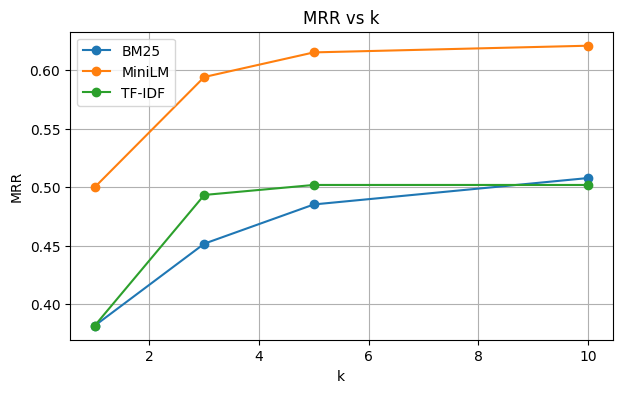

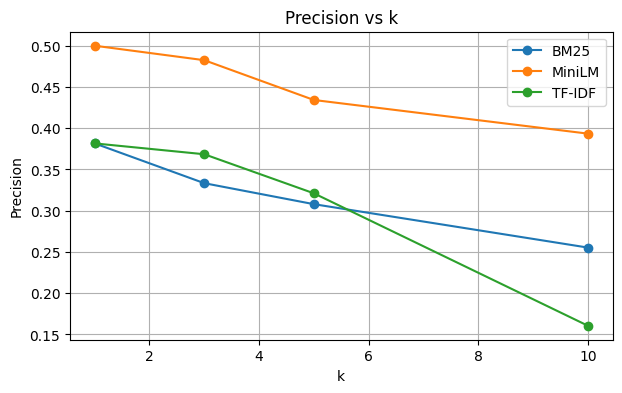

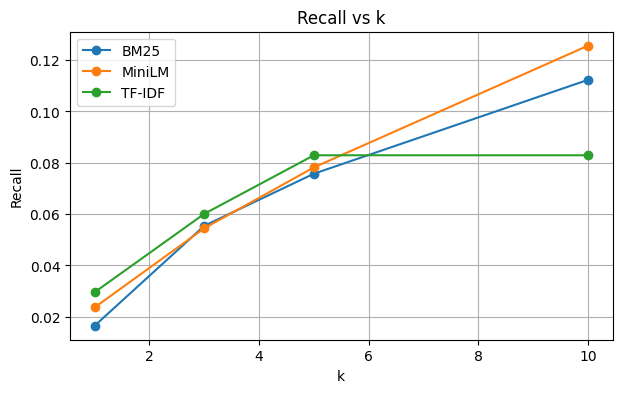

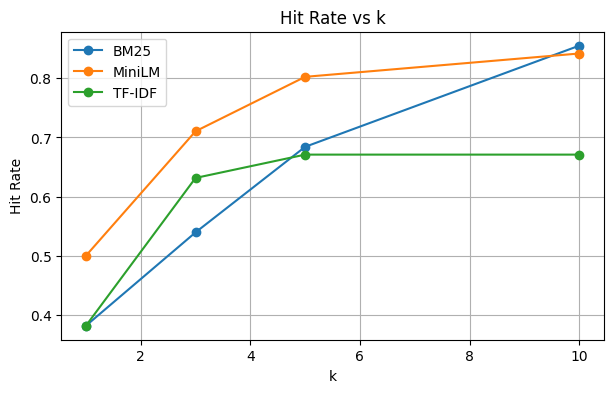

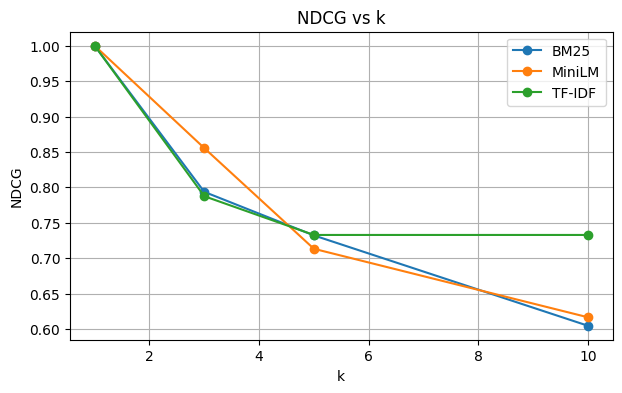

           MRR  Precision  Recall  Hit Rate    NDCG
model                                              
MiniLM  0.5827     0.4525  0.0705    0.7138  0.7963
TF-IDF  0.4697     0.3079  0.0639    0.5888  0.8133
BM25    0.4566     0.3195  0.0650    0.6151  0.7826


In [ ]:
import matplotlib.pyplot as plt

combined = pd.concat([
    tf_idf_eval_df.assign(model="TF-IDF"),
    bm25_eval_results.assign(model="BM25"),
    minilm_eval_results.assign(model="MiniLM"),
])


metrics = ["MRR", "Precision", "Recall", "Hit Rate", "NDCG"]

for metric in metrics:
    plt.figure(figsize=(7,4))
    for model, df in combined.groupby("model"):
        plt.plot(df["k"], df[metric], marker="o", label=model)
    plt.title(f"{metric} vs k")
    plt.xlabel("k")
    plt.ylabel(metric)
    plt.legend()
    plt.grid(True)
    plt.show()

# Simple ranking summary
summary = (
    combined.groupby("model")[metrics]
    .mean()
    .sort_values(by="MRR", ascending=False)
)
print(summary.round(4))

🧠 Interpretation
1. MiniLM — Clear Winner
✅ Highest MRR, Precision, and Hit Rate → it ranks relevant docs highest most consistently.
✅ Outperforms both BM25 and TF-IDF by a wide margin on ranking-sensitive metrics.
⚠️ Recall is only slightly better than TF-IDF and BM25 — meaning it’s not retrieving more unique relevant docs, but it’s ordering them better.
💬 Conclusion: MiniLM provides semantic accuracy and top-rank relevance, ideal for real-world dense retrieval or RAG systems.
2. TF-IDF — Decent Sparse Baseline
✅ High NDCG → normalizes well due to perfect top-1 hits (k=1).
⚠️ But precision and recall drop quickly as k increases → keyword-only signals limit generalization.
💬 Conclusion: A good benchmark, but weak at capturing meaning or synonyms.
3. BM25 — Better Recall but Less Precision
✅ Slightly higher recall than TF-IDF → finds more relevant documents deeper in the list.
⚠️ Lower precision and NDCG → meaning many of those extra retrieved docs are not ranked well.
💬 Conclusion: BM25 still strong for lexical retrieval (exact keyword match) but loses on semantic relevance.
🧩 Bottom Line
🏆 MiniLM is the best overall retrieval model in your experiment.
It delivers the most relevant top-ranked results with balanced recall, proving the advantage of semantic dense embeddings over keyword-based methods like BM25 and TF-IDF.

### Dense Passage Retrieval 

Having similar idea as Dense Retrieval, it has two main improvements.

1. Instead of single encoder for both documents and queries (or, passages and questions in the paper's terminology), they've trained different.
> *Because the context encoder is not fine-tuned using pairs of questions and answers,  
> the corresponding representations could be suboptimal.*  
>
> — *from* [**Dense Passage Retrieval for Open-Domain Question Answering**](https://arxiv.org/pdf/2004.04906)


Still thinking is it really needed though.


2. MiniLM is trained on Bookcorpus and English wikipedia ([paper](https://arxiv.org/pdf/2002.10957)), trained on general sentence-pair datasets (NLI, STS, paraphrases) or large unlabeled corpora. Dense Passage Retrieval is trained on question-answer pairs which is more suitable for the most cases of retrieval problems.




And a reddit comment about it explains the drawback:


> The main difference is that in the **DPR paper**, they use **two separate encoders** for question and passage,  
> whereas most people nowadays use a **single embedding model** for both.  
> The concept of encoding text and passage as embeddings and using vector search is similar,  
> although that idea predates DPR — and DPR is more than just the inference step.  
> It also refers to the **fine-tuning process** itself.  
>
> As for why DPR seems less popular today, it’s mainly because **fine-tuning is more difficult and time-consuming**,  
> so people prefer to use pretrained models directly.  
> In a **RAG pipeline**, there are often easier ways to improve results — like better **data cleaning, chunking**,  
> or **metadata filtering** — while DPR-style fine-tuning tends to be a **final optimization step**.  
>
> **Key points:**  
> - DPR is a **fine-tuning method**, requiring compute resources many developers don’t have.  
> - It needs **labeled data** (question–passage pairs), which is costly to build.  
> - DPR uses **two encoders**, which makes it less convenient than single-encoder setups —  
>   and in most cases, a single encoder performs well enough.  
> - The **idea behind DPR still persists**: modern embedding models from Cohere or OpenAI  
>   follow a similar training principle but use **one shared model** and **much larger datasets**.  
> - Some variants fine-tune only an **adapter** on top of a pretrained encoder (keeping the passage encoder frozen),  
>   avoiding the need to reindex embeddings after retraining.  
>
> — *Adapted explanation from community discussions on Dense Passage Retrieval (DPR)*  



In [ ]:
from transformers import DPRQuestionEncoder, DPRQuestionEncoderTokenizer, DPRContextEncoder, DPRContextEncoderTokenizer
import torch
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
from tqdm import tqdm

# Load DPR encoders (pretrained, no fine-tuning)
print("🔧 Loading DPR models...")
q_tokenizer = DPRQuestionEncoderTokenizer.from_pretrained("facebook/dpr-question_encoder-single-nq-base")
q_encoder = DPRQuestionEncoder.from_pretrained("facebook/dpr-question_encoder-single-nq-base")

ctx_tokenizer = DPRContextEncoderTokenizer.from_pretrained("facebook/dpr-ctx_encoder-single-nq-base")
ctx_encoder = DPRContextEncoder.from_pretrained("facebook/dpr-ctx_encoder-single-nq-base")

q_encoder.eval()
ctx_encoder.eval()

# Encode all documents (contexts)
print("📝 Encoding all documents with DPR context encoder...")
doc_texts = df['text'].tolist()
doc_embeddings = []

print("Tokenize:")
for text in tqdm(doc_texts):
    inputs = ctx_tokenizer(text, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        embedding = ctx_encoder(**inputs).pooler_output.cpu().numpy()
    doc_embeddings.append(embedding)

doc_embeddings = np.vstack(doc_embeddings)

print(f"✅ Encoded {len(doc_embeddings)} documents!")
print(f"📊 Embedding dimension: {doc_embeddings.shape[1]}")

# Define retrieval function
def rank_with_dpr(query, top_k=5):
    """
    Retrieve top-k passages using DPR pretrained encoders (no fine-tuning).
    """
    inputs = q_tokenizer(query, return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        q_emb = q_encoder(**inputs).pooler_output.cpu().numpy()
    
    similarities = cosine_similarity(q_emb, doc_embeddings)[0]
    top_indices = np.argsort(similarities)[::-1][:top_k]
    top_doc_ids = [df.iloc[idx]['doc_id'] for idx in top_indices]
    return top_doc_ids

# Run DPR retrieval
print("🔍 Starting DPR Vector Search...")

dpr_results = {}
print("Ranking:")

for query_id, query_text in tqdm(queries.items()):
    retrieved_docs = rank_with_dpr(query_text, top_k=10)
    dpr_results[query_id] = retrieved_docs

# Convert results to evaluation format
dpr_eval_results = {}
for query_id, retrieved_docs in dpr_results.items():
    dpr_eval_results[query_id] = {
        "relevancy": mappings.get(query_id),
        "retrieved": retrieved_docs
    }

# Evaluate DPR results
print("\n" + "="*80)
print("📊 DPR VECTOR SEARCH EVALUATION (Pretrained, No Fine-Tuning)")
print("="*80)
dpr_eval_results = evaluate_all_metrics(dpr_eval_results, no_all_docs=1460, k_values=[1, 3, 5, 10])


🔧 Loading DPR models...


Some weights of the model checkpoint at facebook/dpr-question_encoder-single-nq-base were not used when initializing DPRQuestionEncoder: ['question_encoder.bert_model.pooler.dense.bias', 'question_encoder.bert_model.pooler.dense.weight']
- This IS expected if you are initializing DPRQuestionEncoder from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DPRQuestionEncoder from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
The tokenizer class you load from this checkpoint is not the same type as the class this function is called from. It may result in unexpected tokenization. 
The tokenizer class you load from this checkpoint is 'DPRQuestionEncoderTokenizer'. 
The class this function is called from is 'DPRCon

📝 Encoding all documents with DPR context encoder...
✅ Encoded 1460 documents!
📊 Embedding dimension: 768
🔍 Starting DPR Vector Search...

📊 DPR VECTOR SEARCH EVALUATION (Pretrained, No Fine-Tuning)
🔍 INFORMATION RETRIEVAL EVALUATION REPORT
📊 Dataset: 112 total queries, 76 with relevancy data
--------------------------------------------------------------------------------

📈 METRICS OVERVIEW:
 k    MRR Precision Recall Hit Rate  Fallout   NDCG
 1 0.3026    0.3026 0.0091   0.3026 0.000490 1.0000
 3 0.3728    0.2281 0.0213   0.4605 0.001627 0.8420
 5 0.3925    0.1974 0.0288   0.5526 0.002820 0.8077
10 0.4078    0.1658 0.0487   0.6711 0.005865 0.6463

📋 DETAILED METRICS BREAKDOWN

🎯 AT K = 1:
----------------------------------------
  📍 MRR@1   = 0.3026     (Mean Reciprocal Rank)
  🎯 Precision@1  = 0.3026  (Fraction of retrieved that are relevant)
  🔍 Recall@1   = 0.0091     (Fraction of relevant that are retrieved)
  ✅ Hit Rate@1  = 0.3026  (Fraction of queries with at least 1 relevant)


Results doesn't seem to be promising on our dataset/case!

### ColBERT

Let's think about two problems of dense retrievals:

- We have long documents with lots of sentences, and we embed the tokens (words) and average the results into single vector, defining long(and short) document into single vector. We are missing some information over there.

- We have a long query and long document, and may be we have some part (paragraph, word, sentence) of the document which is very relevant to the query.


ColBERT, a late interaction model, embeds tokens of both query and documents independently, calculates similarity between query and document embeddings to have fine-grained semantic similarity, sums over the distance between relations of query/document tokens and re-ranks the results.

![ColBERT visualization from X (Twitter) by @helloiamleonie](https://pbs.twimg.com/media/GWtj2l8WsAAAve7?format=png)

*Image source: [@helloiamleonie on X (Twitter)](https://x.com/helloiamleonie/status/1831667680970948878/photo/1), and Leonie is explaining things [crazy simple.](https://x.com/helloiamleonie/status/1846512890670358661)*


"Oh woh woh, what is late interaction and reranking?"

Let's discuss how ColBERT works!


Paraphrasing [from great IBM article on ColBERT](https://developer.ibm.com/articles/how-colbert-works/):

#### Step 1 – Query and Document Embeddings

Consider the following example:

- **Query (Q):** “largest planet”  
- **Document D₁:** “Jupiter is the largest planet in our solar system.”

Each token is transformed into a numerical embedding.  
For simplicity, assume each token is represented by a 3-dimensional vector (whereas actual models typically use 512–1024 dimensions).

| Text | Tokens |
|-------|---------|
| Query Q | largest, planet |
| Document D₁ | Jupiter, is, the, largest, planet, in, our, solar, system |

#### Step 2 – Token-Level Similarity

For each query token, ColBERT computes its similarity with all document tokens using a dot-product operation:

\[
\text{sim}(a,b) = a_1b_1 + a_2b_2 + a_3b_3
\]

The model calculates similarity scores between “largest” and every token in the document, then repeats the process for “planet.”

#### Step 3 – MaxSim and Aggregation

For each query token, the **maximum similarity (MaxSim)** among document tokens is selected.  
The final relevance score for the document is the **sum** of these MaxSim values across all query tokens.

Example:

\[
\text{Score}(Q, D₁) = \text{MaxSim("largest")} + \text{MaxSim("planet")} = 6 + 4 = 10
\]

Assume there are additional documents D₂, D₃, and D₄ with the following scores:

| Document | Score(Q, D) |
|-----------|-------------|
| D₂ | 12 |
| D₁ | 10 |
| D₃ | 7 |
| D₄ | 3 |

After reranking, the retrieval order would be:  
**D₂ → D₁ → D₃ → D₄**


As you see the nuance, ColBERT doesn't average the BERT output, vector embeddings for tokens are calculated and they are in a bag, rather than being pooled into single vector.[ Also see qdrant blog ](https://qdrant.tech/documentation/fastembed/fastembed-colbert/)


Although we'll use ...

In [ ]:
from transformers import AutoTokenizer, AutoModel
import torch
import torch.nn.functional as F

# Load a small variant of BERT 

bert_mini_model = AutoModel.from_pretrained("jinaai/jina-colbert-v1-en")
bert_mini_tokenizer = AutoTokenizer.from_pretrained("jinaai/jina-colbert-v1-en")


Some weights of BertModel were not initialized from the model checkpoint at jinaai/jina-colbert-v1-en and are newly initialized: ['embeddings.position_embeddings.weight', 'encoder.layer.0.intermediate.dense.bias', 'encoder.layer.0.intermediate.dense.weight', 'encoder.layer.0.output.LayerNorm.bias', 'encoder.layer.0.output.LayerNorm.weight', 'encoder.layer.0.output.dense.bias', 'encoder.layer.0.output.dense.weight', 'encoder.layer.1.intermediate.dense.bias', 'encoder.layer.1.intermediate.dense.weight', 'encoder.layer.1.output.LayerNorm.bias', 'encoder.layer.1.output.LayerNorm.weight', 'encoder.layer.1.output.dense.bias', 'encoder.layer.1.output.dense.weight', 'encoder.layer.10.intermediate.dense.bias', 'encoder.layer.10.intermediate.dense.weight', 'encoder.layer.10.output.LayerNorm.bias', 'encoder.layer.10.output.LayerNorm.weight', 'encoder.layer.10.output.dense.bias', 'encoder.layer.10.output.dense.weight', 'encoder.layer.11.intermediate.dense.bias', 'encoder.layer.11.intermediate.dens

In [ ]:

def generate_embeddings_with_colbert(text, is_query=False):
    prefix = "[Q] " if is_query else "[D] "
    inputs = bert_mini_tokenizer(prefix + str(text), return_tensors="pt", truncation=True, max_length=512)
    with torch.no_grad():
        outputs = bert_mini_model(**inputs)
    emb = outputs.last_hidden_state.squeeze(0)
    emb = F.normalize(emb, p=2, dim=1)
    return emb


As it can be seen, for a single document, we have 11 (for this sentence) vectors rather than one.

In [ ]:
generate_embeddings_with_colbert("Some very long document over here").shape

BertSdpaSelfAttention is used but `torch.nn.functional.scaled_dot_product_attention` does not support non-absolute `position_embedding_type` or `output_attentions=True` or `head_mask`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


torch.Size([11, 768])

In [ ]:
from tqdm import tqdm
# Let's embed tokens of all docs, but not average/pool it, just save it.
doc_embeddings_for_each_token = {}
for id, row in tqdm(df.iterrows()):
    try:
        doc_embeddings_for_each_token[row.doc_id] = generate_embeddings_with_colbert(row.text, is_query=False)
    except:
        pass
# Let's try to search first query on all docs, to do that let's embed query tokens. We'll create function to evaluate all later.
query_embeddings_for_each_token = {}
for id, query_text in tqdm(queries.items()):
    try:
        query_embeddings_for_each_token[int(id)] = generate_embeddings_with_colbert(row.text, is_query=True)
    except: pass


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
1460it [01:47, 13.60it/s]
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 112/112 [00:05<00:00, 21.13it/s]


We have embedded our queries and docs. Now let's calculate the cosine similarity between query 1 and tokens of doc1, then doc2, ...,then doc n. In order to do that, we'll dot product query and doc embeddings. [You can read why dot product becomes cosine similarity in here.](https://community.deeplearning.ai/t/why-is-simple-matmul-of-embedding-vectors-describes-theirs-similarity/673843/24)

In [ ]:
similarities = (query_embeddings_for_each_token[1]@(doc_embeddings_for_each_token[1].T))
print(similarities.shape)
max_per_query, _ = similarities.max(dim=1)
score_of_query_1_on_doc_1= max_per_query.sum()     
print(score_of_query_1_on_doc_1)          

torch.Size([121, 127])
tensor(30.9618)


So for a single doc, we calculate query-doc token-based similarities, then get the maximum relationship between query token and document tokens, assuming the specific token in query (word "COVID" let's say) relates maximum with "SARS" in document queries, leveraging the token-relations.

Let's apply to all.



In [ ]:
from tqdm import tqdm
import torch

def colbert_score(q_emb, d_emb):
    """
    Compute ColBERT late interaction (MaxSim + sum).
    q_emb: [num_q_tokens, dim]
    d_emb: [num_d_tokens, dim]
    """
    sims = torch.matmul(q_emb, d_emb.T)      # cosine similarity matrix
    max_per_query, _ = sims.max(dim=1)       # max similarity per query token
    score = max_per_query.mean()              # sum across query tokens
    return score.item()


def rank_with_colbert(query_id, top_k=5):
    """
    Retrieve top-k docs for given query using ColBERT late interaction.
    """
    q_emb = query_embeddings_for_each_token.get(query_id)
    if q_emb is None:
        return []

    scores = []

    # tqdm on the inner doc loop
    for _, row in tqdm(df.iterrows(),
                       total=len(df),
                       desc=f"Scoring Query {query_id}",
                       leave=False):
        d_emb = doc_embeddings_for_each_token.get(row.doc_id)
        if d_emb is not None:
            try:
                s = colbert_score(q_emb, d_emb)
                scores.append((row.doc_id, s))
            except Exception as e:
                scores.append((row.doc_id, -999))
        else:
            scores.append((row.doc_id, -999))

    # sort descending by score
    top_docs = sorted(scores, key=lambda x: x[1], reverse=True)[:top_k]
    return [doc_id for doc_id, _ in top_docs]


print("🔍 Starting ColBERT Vector Search...")

colbert_results = {}

# tqdm for outer query loop
for query_id in tqdm(query_embeddings_for_each_token.keys(),
                     desc="Processing Queries"):
    retrieved_docs = rank_with_colbert(query_id, top_k=10)
    colbert_results[query_id] = retrieved_docs


colbert_eval_results = {}
for query_id, retrieved_docs in colbert_results.items():
    colbert_eval_results[query_id] = {
        "relevancy": mappings.get(str(query_id)),
        "retrieved": retrieved_docs
    }


print("\n" + "=" * 80)
print("📊 COLBERT-STYLE LATE INTERACTION EVALUATION (MiniBERT)")
print("=" * 80)

colbert_eval_results_df = evaluate_all_metrics(
    colbert_eval_results,
    no_all_docs=len(df),
    k_values=[1, 3, 5, 10]
)


🔍 Starting ColBERT Vector Search...


Processing Queries: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 112/112 [00:18<00:00,  5.94it/s]


📊 COLBERT-STYLE LATE INTERACTION EVALUATION (MiniBERT)
🔍 INFORMATION RETRIEVAL EVALUATION REPORT
📊 Dataset: 112 total queries, 76 with relevancy data
--------------------------------------------------------------------------------

📈 METRICS OVERVIEW:
 k    MRR Precision Recall Hit Rate  Fallout   NDCG
 1 0.0132    0.0132 0.0001   0.0132 0.000695 0.0000
 3 0.0439    0.0263 0.0010   0.0789 0.002058 0.0000
 5 0.0557    0.0263 0.0018   0.1316 0.003430 0.0000
10 0.0648    0.0237 0.0032   0.1974 0.006879 0.0000

📋 DETAILED METRICS BREAKDOWN

🎯 AT K = 1:
----------------------------------------
  📍 MRR@1   = 0.0132     (Mean Reciprocal Rank)
  🎯 Precision@1  = 0.0132  (Fraction of retrieved that are relevant)
  🔍 Recall@1   = 0.0001     (Fraction of relevant that are retrieved)
  ✅ Hit Rate@1  = 0.0132  (Fraction of queries with at least 1 relevant)
  ❌ Fallout@1   = 0.000695  (Fraction of non-relevant retrieved)
  📊 NDCG@1   = 0.0000     (Normalized Discounted Cumulative Gain)

🎯 AT K = 3:

In [ ]:

from ragatouille import RAGPretrainedModel
from tqdm import tqdm
import pandas as pd


print("🔧 Loading Jina-ColBERT via RAGatouille...")
RAG = RAGPretrainedModel.from_pretrained("jinaai/jina-colbert-v1-en")


print("🧠 Indexing all documents...")

RAG.index(collection=df["text"].tolist(), document_ids=df["doc_id"].astype(str), index_name="colbert_demo_index")




🔧 Loading Jina-ColBERT via RAGatouille...


/Users/mehmetburaksayici/Desktop/careeriorepos/resumeio/ai-interview-prep/venv/lib/python3.10/site-packages/colbert/utils/amp.py:12: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler()
/Users/mehmetburaksayici/Desktop/careeriorepos/resumeio/ai-interview-prep/venv/lib/python3.10/site-packages/torch/amp/grad_scaler.py:136: UserWarning: torch.cuda.amp.GradScaler is enabled, but CUDA is not available.  Disabling.
  warnings.warn(


🧠 Indexing all documents...
---- WARNING! You are using PLAID with an experimental replacement for FAISS for greater compatibility ----
This is a behaviour change from RAGatouille 0.8.0 onwards.
This works fine for most users and smallish datasets, but can be considerably slower than FAISS and could cause worse results in some situations.
If you're confident with FAISS working on your machine, pass use_faiss=True to revert to the FAISS-using behaviour.
--------------------


[Oct 13, 12:10:40] #> Note: Output directory .ragatouille/colbert/indexes/colbert_demo_index already exists


[Oct 13, 12:10:40] #> Will delete 10 files already at .ragatouille/colbert/indexes/colbert_demo_index in 20 seconds...
[Oct 13, 12:11:15] [0] 		 #> Encoding 1613 passages..


/Users/mehmetburaksayici/Desktop/careeriorepos/resumeio/ai-interview-prep/venv/lib/python3.10/site-packages/colbert/utils/amp.py:12: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self.scaler = torch.cuda.amp.GradScaler()
/Users/mehmetburaksayici/Desktop/careeriorepos/resumeio/ai-interview-prep/venv/lib/python3.10/site-packages/torch/amp/grad_scaler.py:136: UserWarning: torch.cuda.amp.GradScaler is enabled, but CUDA is not available.  Disabling.
  warnings.warn(
  0%|                                                                                                                                      | 0/50 [00:00<?, ?it/s]/Users/mehmetburaksayici/Desktop/careeriorepos/resumeio/ai-interview-prep/venv/lib/python3.10/site-packages/colbert/utils/amp.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  return torch.cuda.amp.autocast(

[Oct 13, 12:14:05] [0] 		 avg_doclen_est = 134.76998901367188 	 len(local_sample) = 1,613
[Oct 13, 12:14:05] [0] 		 Creating 4,096 partitions.
[Oct 13, 12:14:05] [0] 		 *Estimated* 217,383 embeddings.
[Oct 13, 12:14:05] [0] 		 #> Saving the indexing plan to .ragatouille/colbert/indexes/colbert_demo_index/plan.json ..


...

[Oct 13, 12:18:38] #> Optimizing IVF to store map from centroids to list of pids..
[Oct 13, 12:18:38] #> Building the emb2pid mapping..
[Oct 13, 12:18:38] len(emb2pid) = 217384



100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4096/4096 [00:00<00:00, 103985.55it/s]

[Oct 13, 12:18:38] #> Saved optimized IVF to .ragatouille/colbert/indexes/colbert_demo_index/ivf.pid.pt


Done indexing!


'.ragatouille/colbert/indexes/colbert_demo_index'

In [ ]:
def rank_with_colbert(query_text, top_k=5):
    """
    Retrieve top-k documents using Jina-ColBERT via RAGatouille.
    This automatically handles [Q]/[D] tokens and MaxSim scoring.
    """
    results = RAG.search(query=query_text, k=top_k)
    # RAG returns results with document strings and scores
    ranked_docs =  [r["document_id"] for r in results]
    return ranked_docs



colbert_eval_results = {}
for qid, qtext in tqdm(queries.items()):
    retrieved_ids = rank_with_colbert(qtext, top_k=10)

    colbert_eval_results[qid] = {
        "relevancy": mappings.get(str(qid), []),
        "retrieved": retrieved_ids,
    }

print("\n" + "=" * 80)
print("📊 JINA-COLBERT EVALUATION (RAGatouille)")
print("=" * 80)
colbert_eval_results_df = evaluate_all_metrics(
    colbert_eval_results,
    no_all_docs=len(df),
    k_values=[1, 3, 5, 10]
)


  0%|                                                                                                                                     | 0/112 [00:00<?, ?it/s]/Users/mehmetburaksayici/Desktop/careeriorepos/resumeio/ai-interview-prep/venv/lib/python3.10/site-packages/colbert/utils/amp.py:15: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  return torch.cuda.amp.autocast() if self.activated else NullContextManager()
/Users/mehmetburaksayici/Desktop/careeriorepos/resumeio/ai-interview-prep/venv/lib/python3.10/site-packages/torch/amp/autocast_mode.py:266: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn(
100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 112/112 [00:10<00:00, 10.18it/s]



📊 JINA-COLBERT EVALUATION (RAGatouille)
🔍 INFORMATION RETRIEVAL EVALUATION REPORT
📊 Dataset: 112 total queries, 76 with relevancy data
--------------------------------------------------------------------------------

📈 METRICS OVERVIEW:
 k    MRR Precision Recall Hit Rate  Fallout   NDCG
 1 0.5658    0.5658 0.0361   0.5658 0.000304 1.0000
 3 0.6535    0.5044 0.0699   0.7632 0.001031 0.8018
 5 0.6654    0.4632 0.0954   0.8158 0.001860 0.6846
10 0.6770    0.4026 0.1543   0.9079 0.004110 0.5322

📋 DETAILED METRICS BREAKDOWN

🎯 AT K = 1:
----------------------------------------
  📍 MRR@1   = 0.5658     (Mean Reciprocal Rank)
  🎯 Precision@1  = 0.5658  (Fraction of retrieved that are relevant)
  🔍 Recall@1   = 0.0361     (Fraction of relevant that are retrieved)
  ✅ Hit Rate@1  = 0.5658  (Fraction of queries with at least 1 relevant)
  ❌ Fallout@1   = 0.000304  (Fraction of non-relevant retrieved)
  📊 NDCG@1   = 1.0000     (Normalized Discounted Cumulative Gain)

🎯 AT K = 3:
--------------

Voila! We have the best metrics so far!


## 📚 References & Resources

### Classical Information Retrieval
- [Manning, Raghavan & Schütze — *Introduction to Information Retrieval* (Cambridge University Press, 2008)](https://nlp.stanford.edu/IR-book/)
- [Okapi BM25 — Wikipedia](https://en.wikipedia.org/wiki/Okapi_BM25)
- [Scikit-learn — `TfidfVectorizer`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html)
- [Using TF-IDF to Identify the Signal from the Noise — MungingData Blog](https://mungingdata.wordpress.com/2017/11/25/episode-1-using-tf-idf-to-identify-the-signal-from-the-noise/)

### Dense Retrieval & Sentence Embeddings
- [Sentence-Transformers Library (UKP Lab, DFKI)](https://www.sbert.net/)
- [Hugging Face Model: `all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2)
- [Hugging Face Model: `facebook/dpr-question_encoder-single-nq-base`](https://huggingface.co/facebook/dpr-question_encoder-single-nq-base)
- [Hugging Face Model: `facebook/dpr-ctx_encoder-single-nq-base`](https://huggingface.co/facebook/dpr-ctx_encoder-single-nq-base)

### Late Interaction & Reranking
- [Khattab & Zaharia, 2020 — *ColBERT: Efficient and Effective Passage Search via Contextualized Late Interaction over BERT*](https://arxiv.org/abs/2004.12832)
- [IBM Developer — How ColBERT Works (Visual Explanation)](https://developer.ibm.com/articles/how-colbert-works/)
- [Jina AI — RAGatouille (ColBERT-based Retriever)](https://github.com/jina-ai/ragatouille)
- [Cross-Encoder Rerankers — Hugging Face `cross-encoder/ms-marco-MiniLM-L-6-v2`](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L-6-v2)

### Evaluation Metrics
- [Mean Reciprocal Rank (MRR) — Wikipedia](https://en.wikipedia.org/wiki/Mean_reciprocal_rank)
- [Discounted Cumulative Gain (DCG/NDCG) — Wikipedia](https://en.wikipedia.org/wiki/Discounted_cumulative_gain)
- [Precision, Recall, F1 — Scikit-learn Metrics](https://scikit-learn.org/stable/modules/model_evaluation.html)

### Kaggle Notebooks Referenced
- [Information Retrieval with LangChain — Youssef19](https://www.kaggle.com/code/youssef19/information-retrieval-with-langchain)
- [Evaluating IR on Kaggle Dataset — Sahana Venkatesh](https://www.kaggle.com/code/sahanavejlr/evaluating-ir-on-kaggle-dataset)
- [Introduction to Information Retrieval — V. Batista](https://www.kaggle.com/code/vabatista/introduction-to-information-retrieval/notebook)
- *Kudos to [Sahana Venkatesh](https://www.kaggle.com/code/sahanavejlr/evaluating-ir-on-kaggle-dataset)* for the evaluation framework inspiration.

### Additional Libraries / Tools
- [FAISS — Facebook AI Similarity Search](https://github.com/facebookresearch/faiss)
- [Pyserini — Toolkit for Reproducible IR Research](https://github.com/castorini/pyserini)
- [BEIR Benchmark — Hugging Face Dataset](https://huggingface.co/datasets/beir)

### Image & Media Credits
- *Image source:* [@helloiamleonie on X (Twitter)](https://x.com/helloiamleonie/status/1831667680970948878/photo/1) — “Leonie explains things crazy simple.”  
